<a href="https://colab.research.google.com/github/Dharshanthisside/ITA0616---Machine-learning/blob/main/Exp_16_Compare_Classification_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             mean_squared_error, r2_score, mean_absolute_error)

                     Accuracy  Precision  Recall      F1
Model                                                   
SVM                    0.9825     0.9726  1.0000  0.9861
Logistic Regression    0.9737     0.9722  0.9859  0.9790
Random Forest          0.9649     0.9589  0.9859  0.9722
Naive Bayes            0.9649     0.9589  0.9859  0.9722
KNN                    0.9474     0.9577  0.9577  0.9577
Decision Tree          0.9474     0.9577  0.9577  0.9577


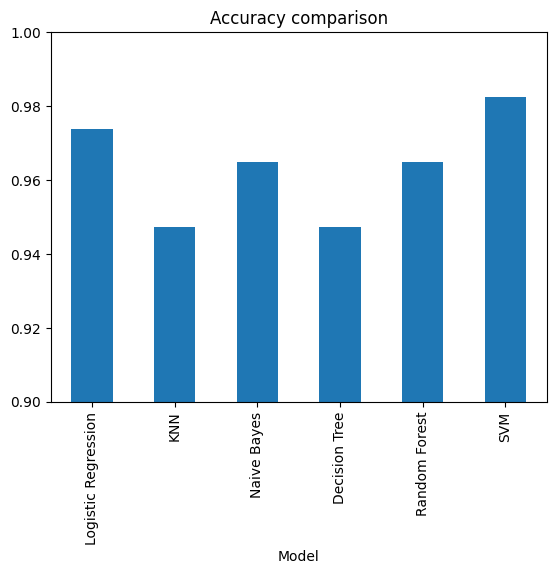

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train, X_test = sc.fit_transform(X_train), sc.transform(X_test)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(5),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append([name, accuracy_score(y_test, p), precision_score(y_test, p),
                 recall_score(y_test, p), f1_score(y_test, p)])

results = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1']).set_index('Model')
print(results.round(4).sort_values('Accuracy', ascending=False))
results['Accuracy'].plot(kind='bar', ylim=(0.9, 1.0), title='Accuracy comparison'); plt.show()